# Detecting change points with PELT

The chosen segmentation balances how well each segment fits against a cost for adding more change points:

$$
(\widehat m,\widehat\tau_1,\ldots,\widehat\tau_{\widehat m})
=\arg\min_{m,\,0=\tau_0<\cdots<\tau_{m+1}=T}
\left\{
\sum_{j=1}^{m+1}C\!\left(y_{\tau_{j-1}+1:\tau_j}\right)
+m\lambda
\right\},
\qquad
\lambda=\kappa\log T.
$$

Here, $T$ is series length; $m$ is the number of change points; $\tau_j$ is boundary $j.$ $y_{a:b}$ is the segment from $a$ through $b$; $C$ is its lack-of-fit cost; $\lambda$ is the cost per change point. $\kappa$ is the penalty multiplier; $\log$ is the natural logarithm; $\arg\min$ selects the segmentation with the smallest total.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import warnings
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
from RiskLabAI.features.structural_breaks import compute_beta, get_bsadf_sequence, get_bubble_episodes, get_expanding_window_adf, get_gsadf_statistic, get_sadf_sequence, pelt_change_points, prepare_data, psy_minimum_window, simulate_psy_critical_values, volatility_robust_sadf
DATA_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=NASDAQCOM&cosd=1994-01-01&coed=2025-12-31'
DATA_DIR = ROOT / 'data' / 'public' / 'fred'
DATA_PATH = ensure_dataset(ROOT, 'fred_nasdaq')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
raw = pd.read_csv(DATA_PATH, parse_dates=['observation_date'])
raw['NASDAQCOM'] = pd.to_numeric(raw['NASDAQCOM'], errors='coerce')
daily_price = raw.set_index('observation_date')['NASDAQCOM'].dropna().sort_index()
monthly_price = daily_price.resample('ME').last().dropna()
log_price = np.log(monthly_price).rename('log_price')
monthly_return = log_price.diff().dropna().rename('log_return')
FIGURES = ROOT / 'outputs' / 'figures' / '12_structural_breaks'
TABLES = ROOT / 'outputs' / 'tables' / '12_structural_breaks'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})
warnings.filterwarnings('ignore', message='New behaviour in v1.1.5.*')

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Detecting changes in public moments

,Penalty multiplier,Penalty,Change points,Boundary dates
0,1.5,8.922052,7,"1998-08-31, 2003-01-31, 2007-11-30, 2009-03-31..."
1,2,11.896070,6,"1998-08-31, 2003-01-31, 2007-11-30, 2009-03-31..."
2,2.5,14.870087,5,"1998-08-31, 2003-01-31, 2007-11-30, 2012-06-30..."
3,3,17.844105,2,"1998-08-31, 2003-01-31"
4,4,23.792140,2,"1998-08-31, 2003-01-31"
5,6,35.688210,2,"1998-08-31, 2003-01-31"
6,8,47.584280,1,2003-01-31
7,10,59.480350,0,None


,Segment,First month,Last month,Months,"Annualized mean, percent","Annualized volatility, percent"
0,1,1994-02-28,1998-07-31,54,18.883820,15.496235
1,2,1998-08-31,2002-12-31,53,-7.650621,40.277766
2,3,2003-01-31,2025-12-31,276,12.420206,17.526692


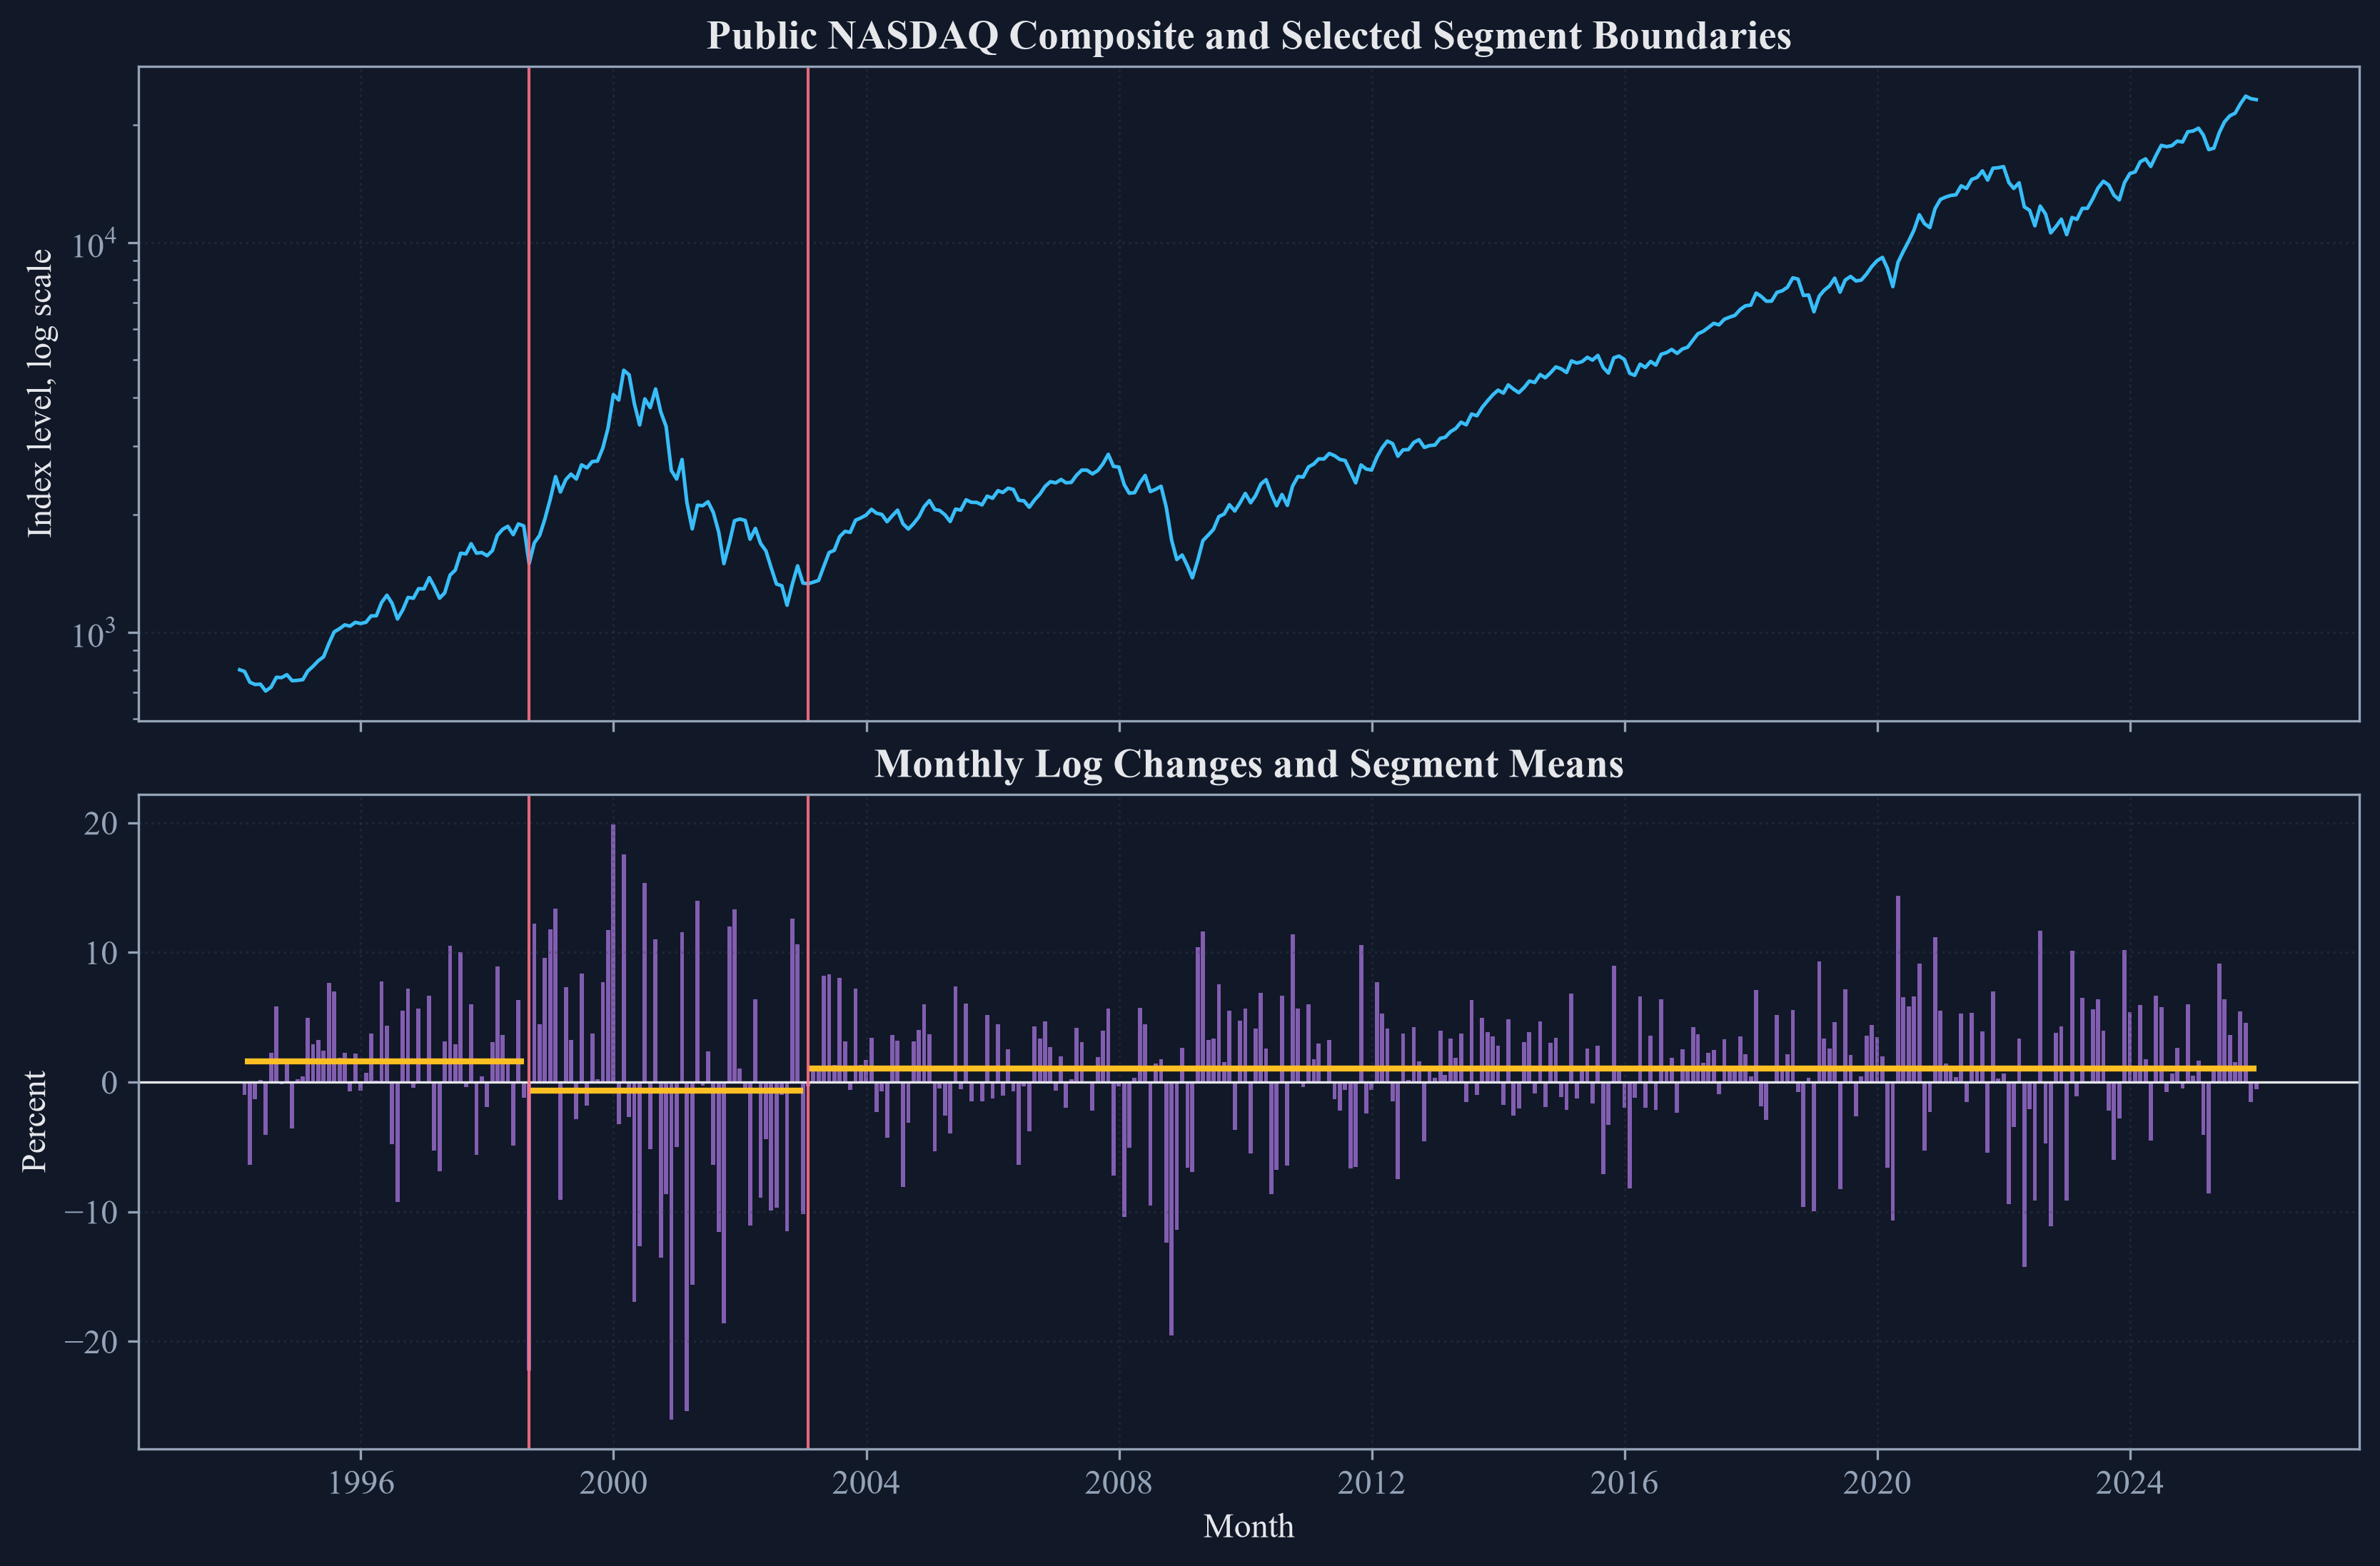

In [2]:
public_penalties = [1.5, 2.0, 2.5, 3.0, 4.0, 6.0, 8.0, 10.0]
public_penalty_rows = []
public_boundaries = {}
for multiplier in public_penalties:
    boundaries = pelt_change_points(monthly_return, model="normal", penalty_multiplier=multiplier, min_size=12, jump=1)
    public_boundaries[multiplier] = boundaries
    boundary_dates = [str(monthly_return.index[position].date()) for position in boundaries]
    public_penalty_rows.append({"Penalty multiplier": multiplier, "Penalty": multiplier * np.log(len(monthly_return)), "Change points": len(boundaries), "Boundary dates": ", ".join(boundary_dates) if boundary_dates else "None"})
pelt_public_penalties = pd.DataFrame(public_penalty_rows)
save_table(pelt_public_penalties, "pelt_public_penalties", "Sensitivity of public change points to the penalty multiplier. Every month is an admissible boundary.", "tab:chapter11-pelt-public-penalties", fit=True)
display(pelt_public_penalties.round(6))

chosen_multiplier = 3.0
chosen_boundaries = public_boundaries[chosen_multiplier]
segment_edges = [0] + chosen_boundaries + [len(monthly_return)]
public_segment_rows = []
for segment_number, (left, right) in enumerate(zip(segment_edges[:-1], segment_edges[1:]), start=1):
    segment = monthly_return.iloc[left:right]
    public_segment_rows.append({"Segment": segment_number, "First month": str(segment.index.min().date()), "Last month": str(segment.index.max().date()), "Months": len(segment), "Annualized mean, percent": 1200 * segment.mean(), "Annualized volatility, percent": 100 * np.sqrt(12) * segment.std(ddof=1)})
pelt_public_segments = pd.DataFrame(public_segment_rows)
save_table(pelt_public_segments, "pelt_public_segments", "Public NASDAQ log-change segments at penalty multiplier 3.", "tab:chapter11-pelt-public-segments", fit=True)
display(pelt_public_segments.round(6))

boundary_dates = [monthly_return.index[position] for position in chosen_boundaries]
figure, axes = plt.subplots(2, 1, figsize=(11.0, 7.2), sharex=True, constrained_layout=True)
axes[0].plot(monthly_price.index, monthly_price, color=palette["cyan"], linewidth=1.2)
axes[0].set_yscale("log")
axes[0].set_title("Public NASDAQ Composite and Selected Segment Boundaries")
axes[0].set_ylabel("Index level, log scale")
axes[0].grid(alpha=0.35)
axes[1].bar(monthly_return.index, 100 * monthly_return, width=24, color=palette["violet"], alpha=0.65)
for left, right, row in zip(segment_edges[:-1], segment_edges[1:], public_segment_rows):
    segment_index = monthly_return.index[left:right]
    axes[1].hlines(row["Annualized mean, percent"] / 12, segment_index.min(), segment_index.max(), color=palette["amber"], linewidth=2.0)
axes[1].axhline(0, color=palette["text"], linewidth=0.8)
axes[1].set_title("Monthly Log Changes and Segment Means")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Percent")
axes[1].grid(alpha=0.35)
for axis in axes:
    for date in boundary_dates:
        axis.axvline(date, color=palette["rose"], linewidth=1.0, alpha=0.9)
locator = mdates.AutoDateLocator(minticks=6, maxticks=10)
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
figure.savefig(FIGURES / "pelt_public_segments.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "pelt_public_segments.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "pelt_public_segments.png")))
plt.close(figure)

## How PELT pruning follows the recursion

The recursion builds an optimal segmentation from earlier optimal pieces, and the inequality removes a candidate that cannot become best later:

$$
F(s)=\min_{0\leq t<s}\left\{F(t)+C(y_{t+1:s})+\lambda\right\},
\qquad
F(t)+C(y_{t+1:s})+K\geq F(s)
\ \Longrightarrow\ 
t\text{ may be removed from later searches}.
$$

Here, $F(s)$ is the smallest penalized cost through observation $s$; $t$ is a candidate last boundary before $s.$ $C(y_{t+1:s})$ is the cost of the last segment; $\lambda$ is the cost per boundary; $K$ is a constant allowed by the segment cost. $\min$ selects the smallest candidate cost; $\Longrightarrow$ states the pruning implication.

## A Known-Truth Segmentation

The controlled series has one mean change, one pure variance change, and one combined mean and variance change:

$$
X_t\sim\mathcal N(\mu_j,\sigma_j^2),
\qquad
(\tau_1,\tau_2,\tau_3)=(60,140,195),
\qquad
(\mu_j)=(0,1.2,1.2,-0.8),
\qquad
(\sigma_j)=(1,1,2.5,1).
$$

Here, $X_t$ is observation $t$; $\mathcal N(\mu_j,\sigma_j^2)$ is a normal distribution in segment $j.$ $\tau_1,\tau_2,\tau_3$ are the known boundaries; $\mu_j$ is the segment mean; $\sigma_j$ is the segment standard deviation. $t$ runs from 0 through 239; the four segment lengths are $60,80,55,$ and $45.$

,Item,Value
0,Observations,240
1,True boundaries,"60, 140, 195"
2,Segment lengths,"60, 80, 55, 45"
3,Segment means,"0, 1.2, 1.2, -0.8"
4,Segment standard deviations,"1, 1, 2.5, 1"
5,Repetitions,24
6,Match tolerance,10
7,Minimum segment,15
8,Candidate spacing,1


,Segment cost,Penalty multiplier,Boundary recall,Pure-variance recall,False boundaries per path,Exact three-boundary paths,Mean location error
0,Mean and variance,2,0.972222,0.958333,0.250000,0.791667,1.385714
1,Mean and variance,3,0.972222,0.958333,0.083333,0.916667,1.371429
2,Mean and variance,6,0.916667,0.916667,0.041667,0.750000,1.454545
3,Mean only,3,0.666667,0.291667,0.916667,0.041667,2.187500


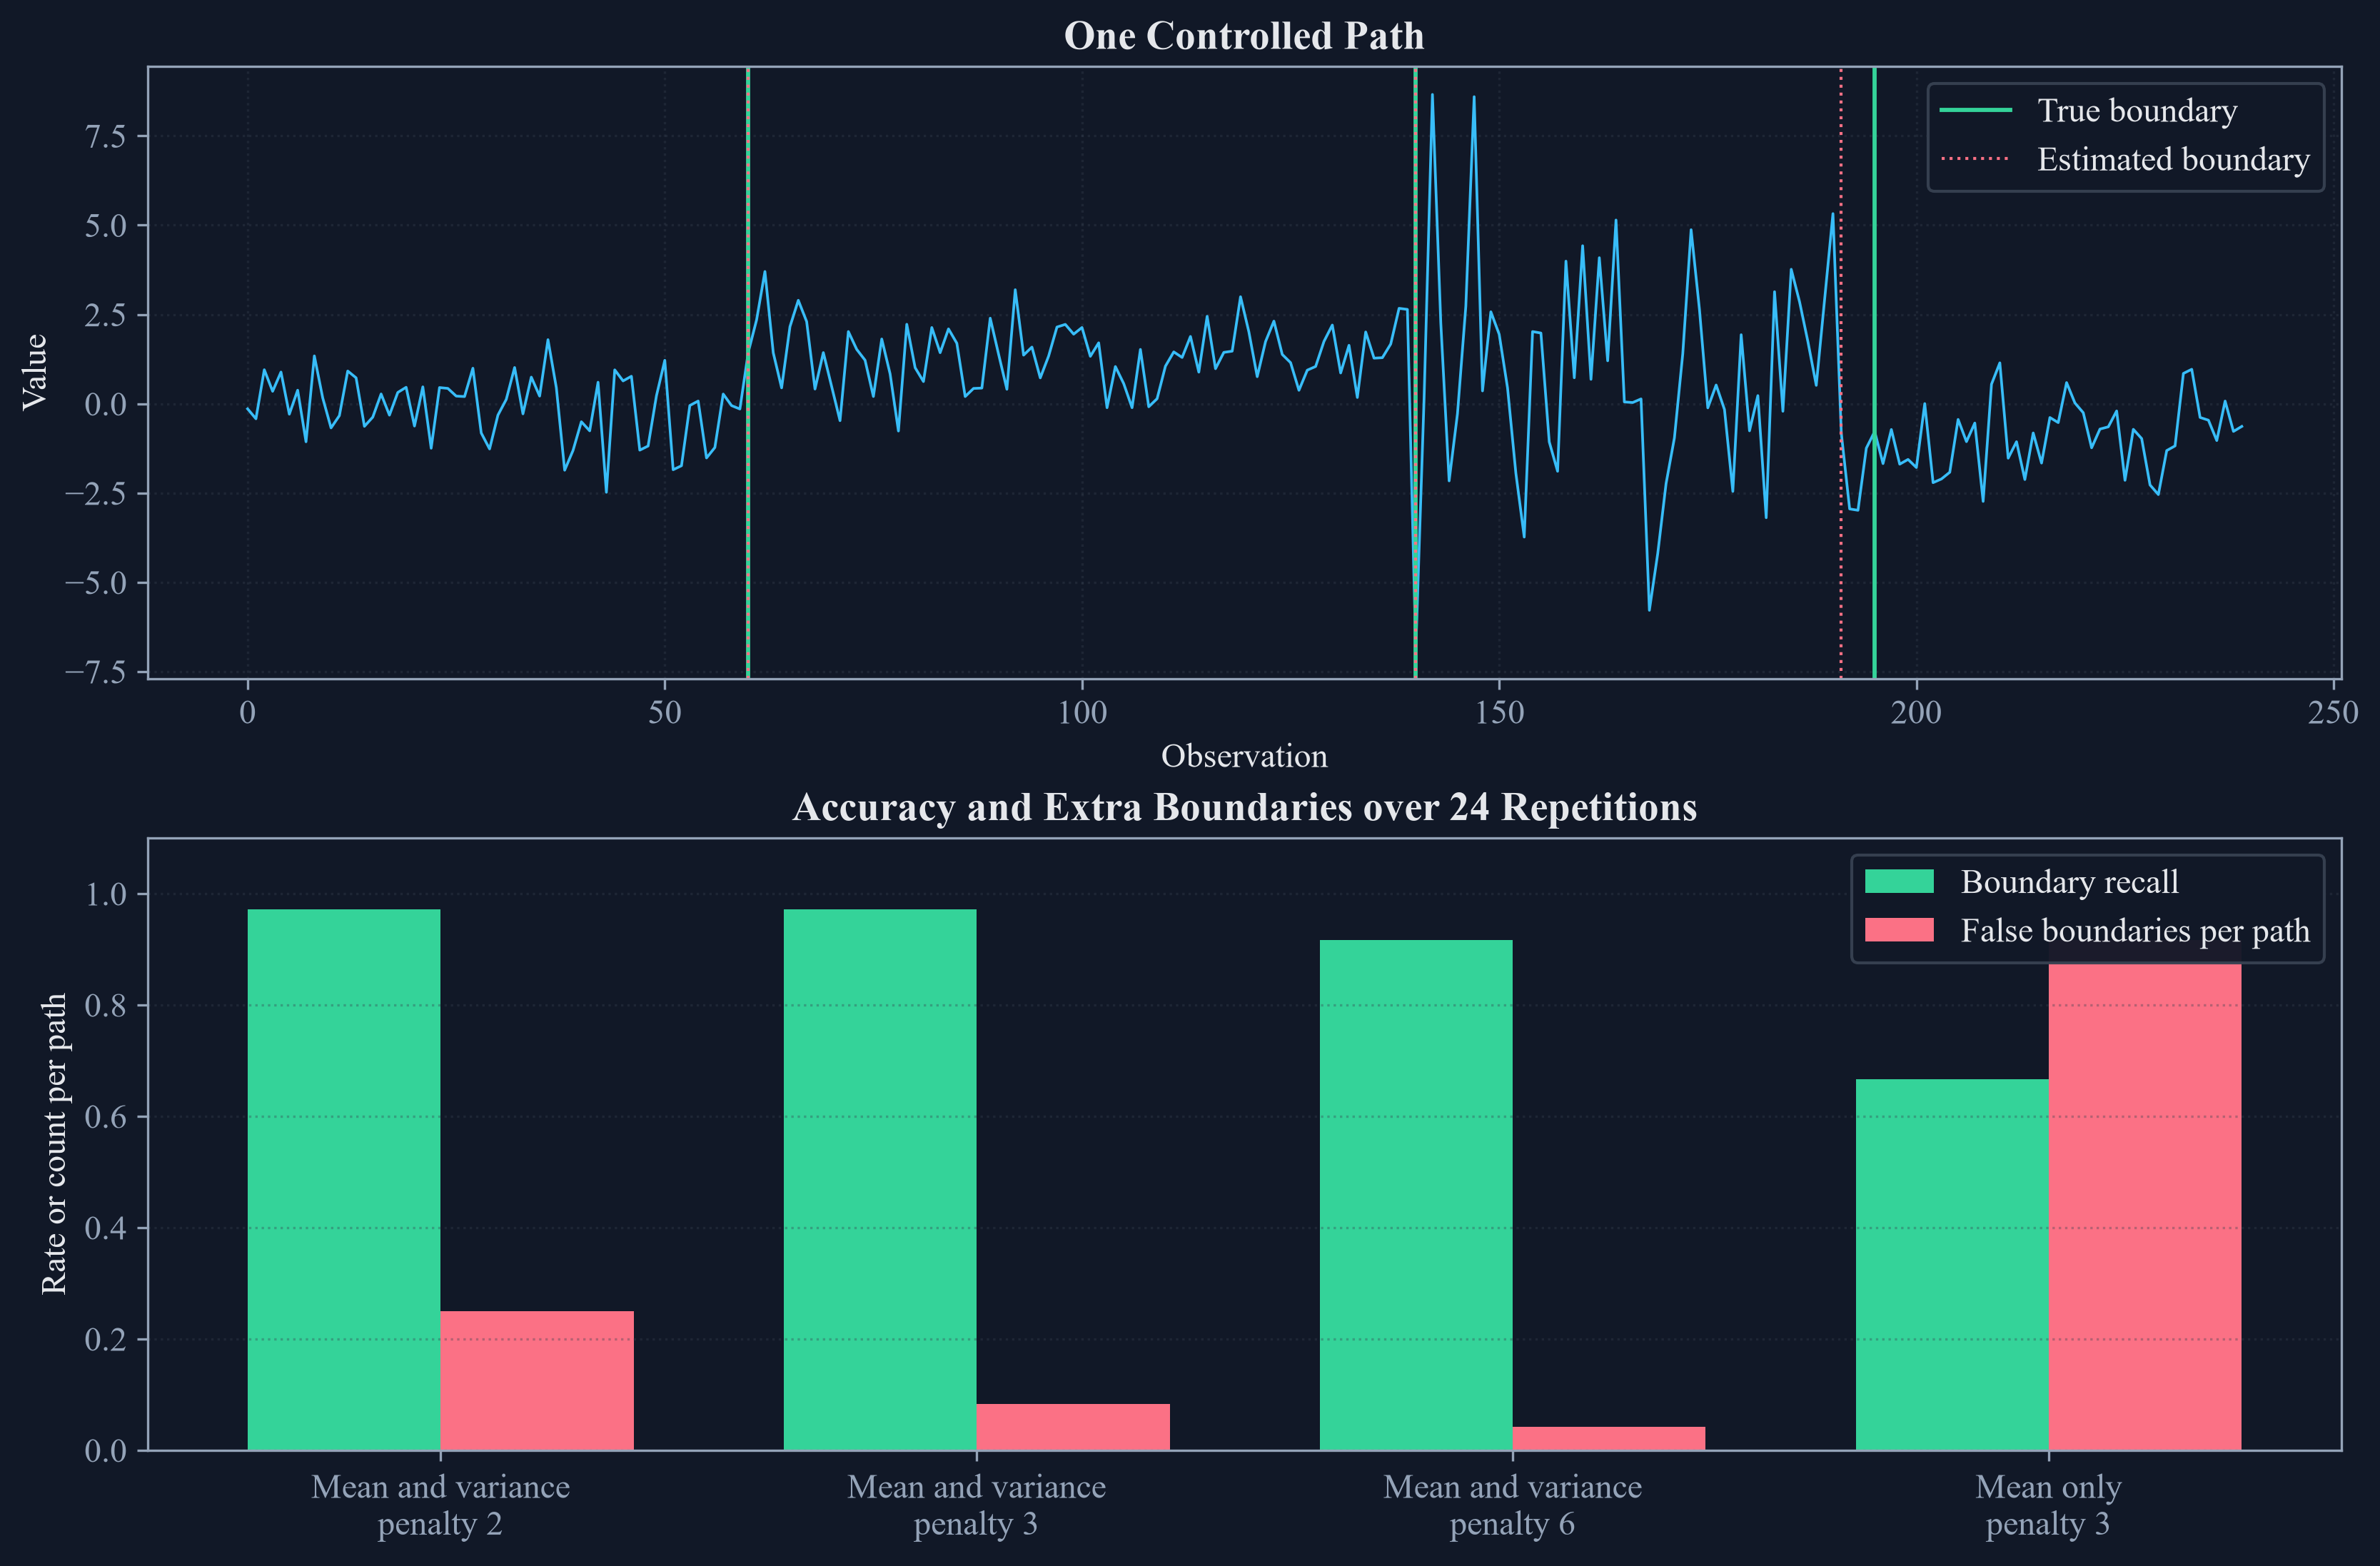

In [3]:
true_boundaries = [60, 140, 195]
segment_lengths = [60, 80, 55, 45]
segment_means = [0.0, 1.2, 1.2, -0.8]
segment_standard_deviations = [1.0, 1.0, 2.5, 1.0]
controlled_repetitions = 24
matching_tolerance = 10
controlled_configurations = [("Mean and variance", 2.0), ("Mean and variance", 3.0), ("Mean and variance", 6.0), ("Mean only", 3.0)]
pelt_controlled_design = pd.DataFrame({
    "Item": ["Observations", "True boundaries", "Segment lengths", "Segment means", "Segment standard deviations", "Repetitions", "Match tolerance", "Minimum segment", "Candidate spacing"],
    "Value": ["240", "60, 140, 195", "60, 80, 55, 45", "0, 1.2, 1.2, -0.8", "1, 1, 2.5, 1", str(controlled_repetitions), str(matching_tolerance), "15", "1"],
})
save_table(pelt_controlled_design, "pelt_controlled_design", "Known-truth change-point experiment.", "tab:chapter11-pelt-controlled-design", fit=False)
display(pelt_controlled_design)

def generate_controlled_series(seed):
    current_rng = np.random.default_rng(seed)
    return np.concatenate([current_rng.normal(mean, standard_deviation, length) for length, mean, standard_deviation in zip(segment_lengths, segment_means, segment_standard_deviations)])

def match_boundaries(predicted):
    remaining = list(predicted)
    errors = []
    matched_truth = []
    for truth in true_boundaries:
        candidates = [value for value in remaining if abs(value - truth) <= matching_tolerance]
        if candidates:
            chosen = min(candidates, key=lambda value: abs(value - truth))
            remaining.remove(chosen)
            errors.append(abs(chosen - truth))
            matched_truth.append(truth)
    return matched_truth, remaining, errors

controlled_rows = []
for cost_name, multiplier in controlled_configurations:
    model = "normal" if cost_name == "Mean and variance" else "l2"
    matched_total = 0
    variance_matches = 0
    false_total = 0
    exact_total = 0
    all_errors = []
    for repetition in range(controlled_repetitions):
        controlled_values = generate_controlled_series(12000 + repetition)
        predicted = pelt_change_points(controlled_values, model=model, penalty_multiplier=multiplier, min_size=15, jump=1)
        matched_truth, remaining, errors = match_boundaries(predicted)
        matched_total += len(matched_truth)
        variance_matches += 140 in matched_truth
        false_total += len(remaining)
        exact_total += len(matched_truth) == len(true_boundaries) and len(remaining) == 0
        all_errors.extend(errors)
    controlled_rows.append({"Segment cost": cost_name, "Penalty multiplier": multiplier, "Boundary recall": matched_total / (controlled_repetitions * len(true_boundaries)), "Pure-variance recall": variance_matches / controlled_repetitions, "False boundaries per path": false_total / controlled_repetitions, "Exact three-boundary paths": exact_total / controlled_repetitions, "Mean location error": np.mean(all_errors)})
pelt_controlled_accuracy = pd.DataFrame(controlled_rows)
save_table(pelt_controlled_accuracy, "pelt_controlled_accuracy", "Known-truth change-point accuracy across segment costs and penalties.", "tab:chapter11-pelt-controlled-accuracy", fit=True)
display(pelt_controlled_accuracy.round(6))

example_values = generate_controlled_series(12000)
example_boundaries = pelt_change_points(example_values, model="normal", penalty_multiplier=3.0, min_size=15, jump=1)
figure, axes = plt.subplots(2, 1, figsize=(11.0, 7.2), constrained_layout=True)
axes[0].plot(example_values, color=palette["cyan"], linewidth=0.9)
for boundary in true_boundaries:
    axes[0].axvline(boundary, color=palette["green"], linewidth=1.4, label="True boundary" if boundary == true_boundaries[0] else None)
for boundary in example_boundaries:
    axes[0].axvline(boundary, color=palette["rose"], linewidth=1.0, linestyle=":", label="Estimated boundary" if boundary == example_boundaries[0] else None)
axes[0].set_title("One Controlled Path")
axes[0].set_xlabel("Observation")
axes[0].set_ylabel("Value")
axes[0].legend()
axes[0].grid(alpha=0.35)
positions = np.arange(len(pelt_controlled_accuracy))
axes[1].bar(positions - 0.18, pelt_controlled_accuracy["Boundary recall"], 0.36, color=palette["green"], label="Boundary recall")
axes[1].bar(positions + 0.18, pelt_controlled_accuracy["False boundaries per path"], 0.36, color=palette["rose"], label="False boundaries per path")
labels = [f"{row['Segment cost']}\npenalty {row['Penalty multiplier']:g}" for row in controlled_rows]
axes[1].set_xticks(positions, labels)
axes[1].set_ylim(0, max(1.1, 1.1 * pelt_controlled_accuracy[["Boundary recall", "False boundaries per path"]].to_numpy().max()))
axes[1].set_title("Accuracy and Extra Boundaries over 24 Repetitions")
axes[1].set_ylabel("Rate or count per path")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.35)
figure.savefig(FIGURES / "pelt_known_truth.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "pelt_known_truth.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "pelt_known_truth.png")))
plt.close(figure)

## Tests

In [4]:
assert len(monthly_return) == 383
assert public_penalties == sorted(public_penalties)
assert pelt_public_penalties.shape == (8, 4)
assert pelt_public_penalties['Change points'].is_monotonic_decreasing
assert public_boundaries[3.0] == [54, 107]
assert chosen_boundaries == [54, 107]
assert [str(value.date()) for value in boundary_dates] == ['1998-08-31', '2003-01-31']
assert len(pelt_public_segments) == 3
assert pelt_public_segments['Months'].sum() == len(monthly_return)
assert pelt_public_segments['Months'].min() >= 12
assert pelt_public_segments['Annualized volatility, percent'].gt(0).all()
assert true_boundaries == [60, 140, 195]
assert sum(segment_lengths) == 240
assert controlled_repetitions == 24
assert pelt_controlled_accuracy.shape == (4, 7)
assert pelt_controlled_accuracy['Boundary recall'].between(0, 1).all()
assert pelt_controlled_accuracy['Pure-variance recall'].between(0, 1).all()
assert pelt_controlled_accuracy['False boundaries per path'].ge(0).all()
assert pelt_controlled_accuracy['Exact three-boundary paths'].between(0, 1).all()
assert pelt_controlled_accuracy['Mean location error'].le(matching_tolerance).all()
assert pelt_controlled_accuracy.iloc[1]['Boundary recall'] >= 0.9
assert pelt_controlled_accuracy.iloc[1]['Pure-variance recall'] >= 0.9
assert pelt_controlled_accuracy.iloc[1]['False boundaries per path'] <= 0.2
assert pelt_controlled_accuracy.iloc[1]['Exact three-boundary paths'] >= 0.8
assert pelt_controlled_accuracy.iloc[1]['Pure-variance recall'] > pelt_controlled_accuracy.iloc[3]['Pure-variance recall']
assert all((abs(value - truth) <= matching_tolerance for value, truth in zip(example_boundaries, true_boundaries)))
assert (FIGURES / 'pelt_public_segments.pdf').is_file()
assert (FIGURES / 'pelt_known_truth.pdf').is_file()
assert (TABLES / 'pelt_public_penalties.tex').is_file()
assert (TABLES / 'pelt_public_segments.tex').is_file()
assert (TABLES / 'pelt_controlled_design.tex').is_file()
assert (TABLES / 'pelt_controlled_accuracy.tex').is_file()
